In [1]:
energy={}
try:
    with open('data/energy.csv','r',encoding='utf-8') as f:
        for line in f:
            line=line.strip()
            if not line:
                continue
            parts=line.replace('，',',').split(',')
            if len(parts)<3:
                print(f"数据缺失：{line}")
                continue
            name=parts[0]
            km=int(parts[1])
            kwh=int(parts[2])
            energy[name]=[km,kwh]
except FileNotFoundError:
    print("错误：未检查到energy.csv，请检查data目录")
except Exception as e:
    print(f"未知错误：{e}")
ridership={}
try:
    with open('data/ridership.txt','r',encoding='utf-8') as f:
        for line in f:
            line=line.strip()
            if not line:
                continue
            parts=line.replace('，',',').split(',')
            if len(parts)<2:
                print(f"数据不完整：{line}")
                continue
            name=parts[0]
            count=int(parts[1])
            ridership[name]=count
except FileNotFoundError:
    print("错误：未找到ridership.txt")
except Exception as e:
    print(f"未知错误：{e}")
def calculate_intensity(energy,ridership):
    intensity={}
    lines=[]
    try:
        for name in ridership:
            kwh=energy[name][1]
            count=ridership[name]
            if count==0:
                continue
            intensity[name]=kwh/count*10000
            lines.append(f"{name}:{intensity[name]:.2f}kwh/万人次")
        return(intensity,lines)
    except Exception as e:
        print(f"未知错误：{e}")

In [2]:
intensity, lines = calculate_intensity(energy, ridership)
print(lines)

['1号线:20833.33kwh/万人次', '2号线:20666.67kwh/万人次', '3号线:24444.44kwh/万人次']


In [3]:
def generate_report(lines,intensity,filename='output_report.txt'):
    if not intensity:
        print("无可用数据，无法计算")
        return
    widest=max(len(line) for line in lines)
    lines.insert(0,"地铁客流与能耗情况")
    lines.insert(1,"—"*widest)
    lines.insert(2,"")
    min_line=min(intensity,key=intensity.get)
    min_data=intensity[min_line]
    lines.append("")
    lines.append(f"电耗最低的路线为：{min_line},最低能耗为：{min_data:.2f}kwh/万人次")
    report_content='\n'.join(lines)
    try:
        with open(filename,'w',encoding='utf-8') as f:
            f.write(report_content)
            print("报告已生成")
    except FileNotFoundError:
        print("没有检测到output_report.txt")
    except Exception as e:
        print(f"未知错误：{e}")

In [4]:
intensity,lines=calculate_intensity(energy,ridership)
generate_report(lines,intensity,filename='output_report.txt')

报告已生成


In [5]:
def read_energy(path='data/energy.csv'):
    energy={}
    try:
        with open(path,'r',encoding='utf-8') as f:
            for line in f:
                line=line.strip()
                if not line:
                    continue
                parts=line.replace('，',',').split(',')
                if len(parts)<3:
                    print(f"数据缺失：{line}")
                    continue
                name=parts[0]
                km=float(parts[1])
                kwh=float(parts[2])
                energy[name]=[km,kwh]
            return energy
    except fileNotFoundError:
        print(f"没有检测到{path},请自行检查文件是否存在")
    except Exception as e:
        print(f"发现未知错误：{e}")
        return {}

In [6]:
def read_ridership(path='data/ridership.txt'):
    ridership={}
    try:
        with open(path,'r',encoding='utf-8') as f:
            for line in f:
                line=line.strip()
                if not line:
                    continue
                parts=line.replace('，',',').split(',')
                if len(parts)<2:
                    print(f"数据缺失:{line}")
                    continue
                name=parts[0]
                count=float(parts[1])
                ridership[name]=count
            return ridership
    except FlieNotFoundError:
        print(f"未找到{path}")
    except Exception as e:
        print(f"发现未知错误：{e}")
        return {}

In [10]:
def main():
    energy=read_energy()
    ridership=read_ridership()
    intensity,lines=calculate_intensity(energy,ridership)
    generate_report(lines,intensity)
main()

报告已生成


In [11]:
intensity,lines=calculate_intensity(energy,ridership)
print(lines)

['1号线:20833.33kwh/万人次', '2号线:20666.67kwh/万人次', '3号线:24444.44kwh/万人次']


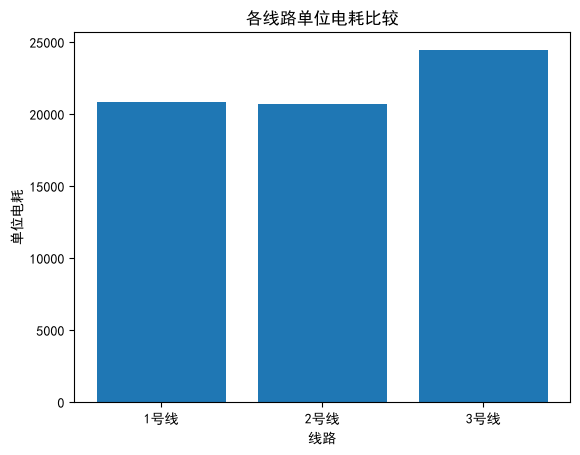

In [13]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif']=['SimHei']
names=list(intensity.keys())
values=list(intensity.values())
plt.bar(names,values)
plt.title("各线路单位电耗比较")
plt.xlabel("线路")
plt.ylabel("单位电耗")
plt.show()